# E-Commerce Customer Churn Classification
**Course:** AIE322 – Advanced Machine Learning  
**University:** New Mansoura University – Faculty of Computer Science & Engineering  
**Student:** [Write your name]  
**Dataset:** E-Commerce Customer Churn Dataset  
**Target:** `Churn` (0 = Retained Customer, 1 = Churned Customer)

## Assignment objective
In this notebook, I build a reproducible binary-classification workflow to predict customer churn. I follow the four parts in the assignment: data inspection and EDA, preprocessing pipelines, model complexity and regularization, and ensemble learning.

> **Before running:** Put `E Commerce Dataset.xlsx` in the same folder as this notebook. If the file has a different name or location, update `DATA_PATH` in the next cell. The dataset is available from the Kaggle page linked in the assignment resources: https://www.kaggle.com/datasets/carrie1/ecommerce-data


## 0. Imports and reproducibility

In [11]:
# If needed, install the required packages:
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    BaggingClassifier, AdaBoostClassifier, RandomForestClassifier, VotingClassifier
)
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

DATA_PATH = "E Commerce Dataset.xlsx"  # Change this if your file has another name


In [12]:
import pandas as pd

file_path = "E Commerce Dataset.xlsx"

excel = pd.ExcelFile(file_path)

print("Available sheets:", excel.sheet_names)

for sheet in excel.sheet_names:
    temp = pd.read_excel(file_path, sheet_name=sheet)
    print("\nSheet:", sheet)
    print("Shape:", temp.shape)
    print("Columns:", temp.columns.tolist())
    display(temp.head(3))

Available sheets: ['Data Dict', 'E Comm']

Sheet: Data Dict
Shape: (21, 4)
Columns: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Data,Variable,Discerption
1,NaN,E Comm,CustomerID,Unique customer ID
2,NaN,E Comm,Churn,Churn Flag



Sheet: E Comm
Shape: (5630, 20)
Columns: ['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28


## Part 1: Data Cleaning, EDA and Reproducible Splitting

### 1.1 Load and inspect the dataset
I first load the Excel file, inspect its dimensions and data types, and check missing values. `CustomerID` is an identifier, so it is removed because it does not describe customer behavior and should not be used as a predictive feature.

In [13]:
# Read the first sheet by default. If your file uses a specific sheet name, set sheet_name="E Comm".
try:
    df = pd.read_excel(DATA_PATH, sheet_name="E Comm")
except FileNotFoundError:
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Put 'E Commerce Dataset.xlsx' beside this notebook "
        "or update DATA_PATH."
    )

print("Dataset shape:", df.shape)
display(df.head())
df.info()
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing values"))


Dataset shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

,Missing values
DaySinceLastOrder,307
OrderAmountHikeFromlastYear,265
Tenure,264
OrderCount,258
CouponUsed,256
HourSpendOnApp,255
WarehouseToHome,251
CustomerID,0
PreferredLoginDevice,0
Churn,0


In [14]:
# Clean column names only by removing leading/trailing spaces.
df.columns = df.columns.astype(str).str.strip()

# Remove the non-predictive identifier when it exists.
id_candidates = [c for c in df.columns if c.lower().replace("_", "") == "customerid"]
if id_candidates:
    df = df.drop(columns=id_candidates)

# Check duplicates before removing them.
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)
df = df.drop_duplicates().copy()
print("Shape after removing duplicate rows:", df.shape)

# Check that the target column exists and is usable.
if "Churn" not in df.columns:
    raise ValueError("The dataset must contain a target column named 'Churn'.")

df["Churn"] = pd.to_numeric(df["Churn"], errors="coerce")
df = df.dropna(subset=["Churn"]).copy()
df["Churn"] = df["Churn"].astype(int)

print("\nTarget values:", sorted(df["Churn"].unique()))
print(df["Churn"].value_counts())


Duplicate rows: 556
Shape after removing duplicate rows: (5074, 19)

Target values: [np.int64(0), np.int64(1)]
Churn
0    4233
1     841
Name: count, dtype: int64


### 1.2 Check possible outliers
I use boxplots to inspect the numerical variables. A point outside the whiskers is a possible outlier, not automatically an error. I therefore inspect these values rather than deleting valid customers without evidence.

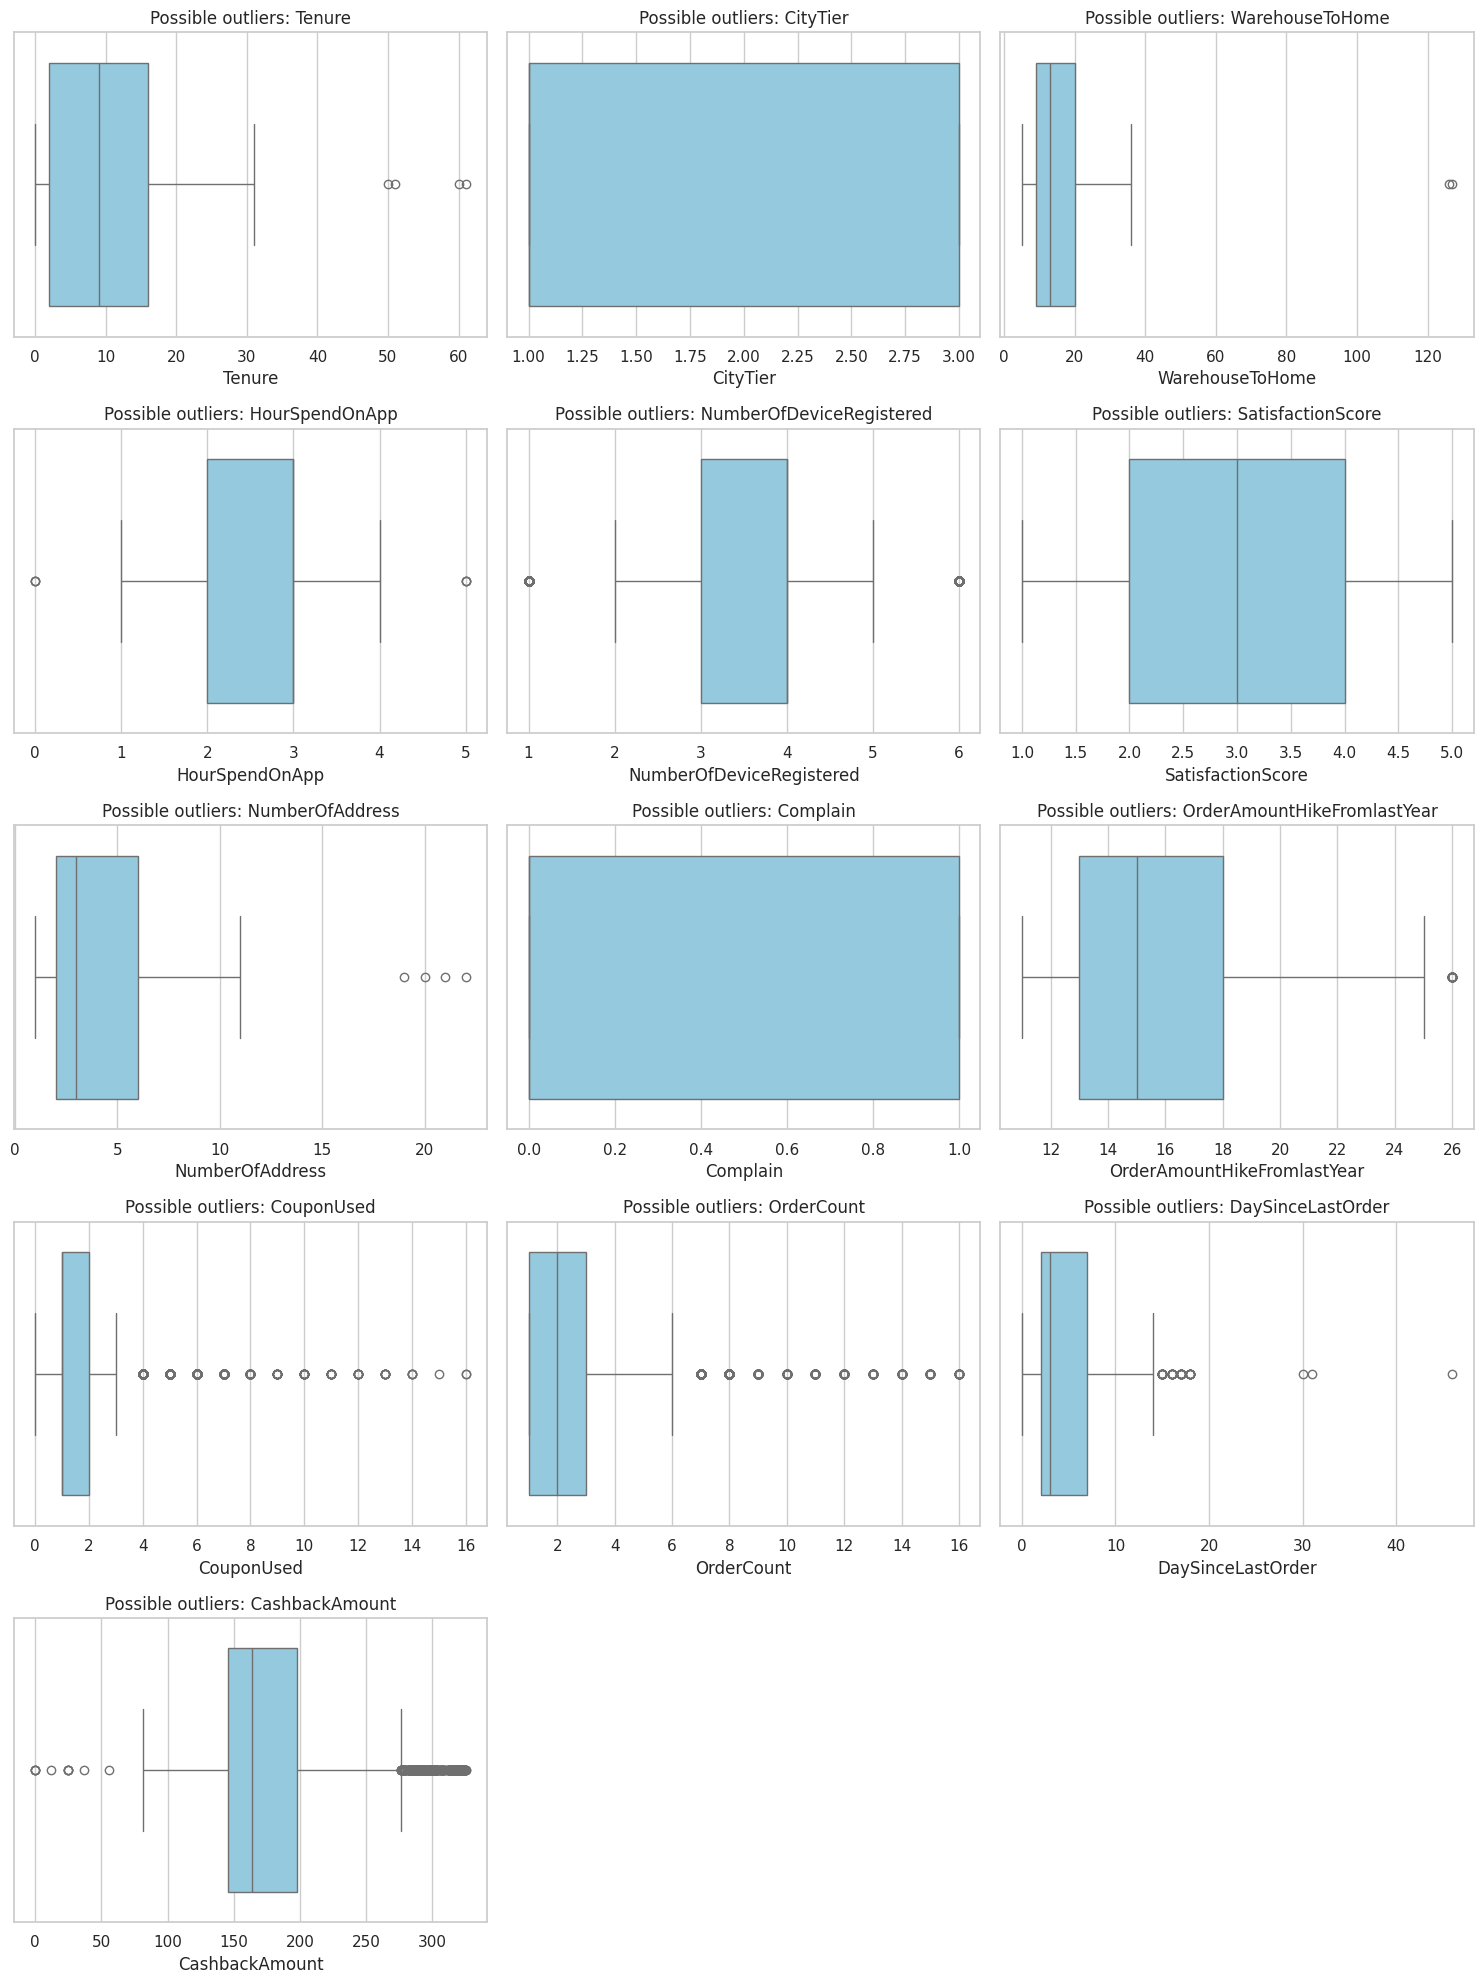

In [15]:
numeric_for_eda = df.select_dtypes(include=np.number).columns.drop("Churn", errors="ignore").tolist()

if numeric_for_eda:
    n_cols = 3
    n_rows = int(np.ceil(len(numeric_for_eda) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, numeric_for_eda):
        sns.boxplot(data=df, x=col, ax=ax, color="skyblue")
        ax.set_title(f"Possible outliers: {col}")
    for ax in axes[len(numeric_for_eda):]:
        ax.remove()
    plt.tight_layout()
    plt.show()
else:
    print("No numerical predictor columns were detected.")


### 1.3 Exploratory Data Analysis (EDA)

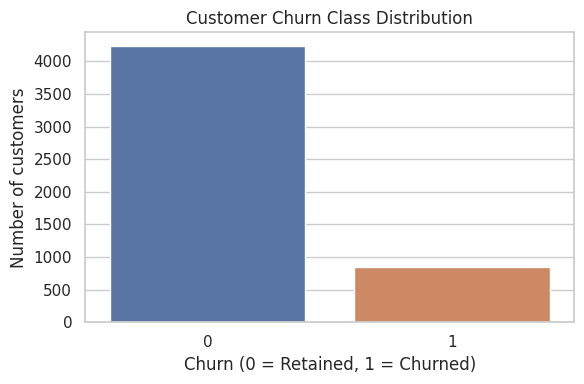

Class percentages:


,Percentage
Churn,
0,83.43
1,16.57


In [16]:
# Churn class balance
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Churn", hue="Churn", legend=False)
ax.set_title("Customer Churn Class Distribution")
ax.set_xlabel("Churn (0 = Retained, 1 = Churned)")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

print("Class percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2).rename("Percentage"))


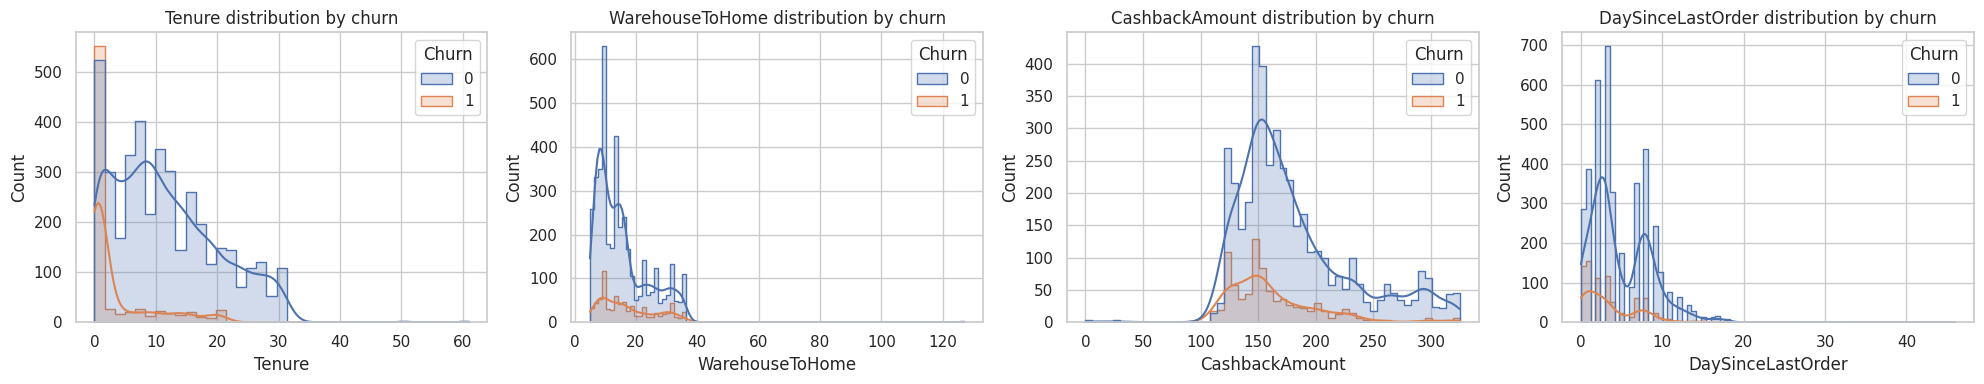

In [17]:
# Numerical features requested in the assignment (plot only those available).
requested_num = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"]
available_num = [c for c in requested_num if c in df.columns]

if available_num:
    fig, axes = plt.subplots(1, len(available_num), figsize=(5 * len(available_num), 4))
    if len(available_num) == 1:
        axes = [axes]
    for ax, col in zip(axes, available_num):
        sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=ax, element="step")
        ax.set_title(f"{col} distribution by churn")
    plt.tight_layout()
    plt.show()
else:
    print("None of the requested numerical EDA columns were found.")


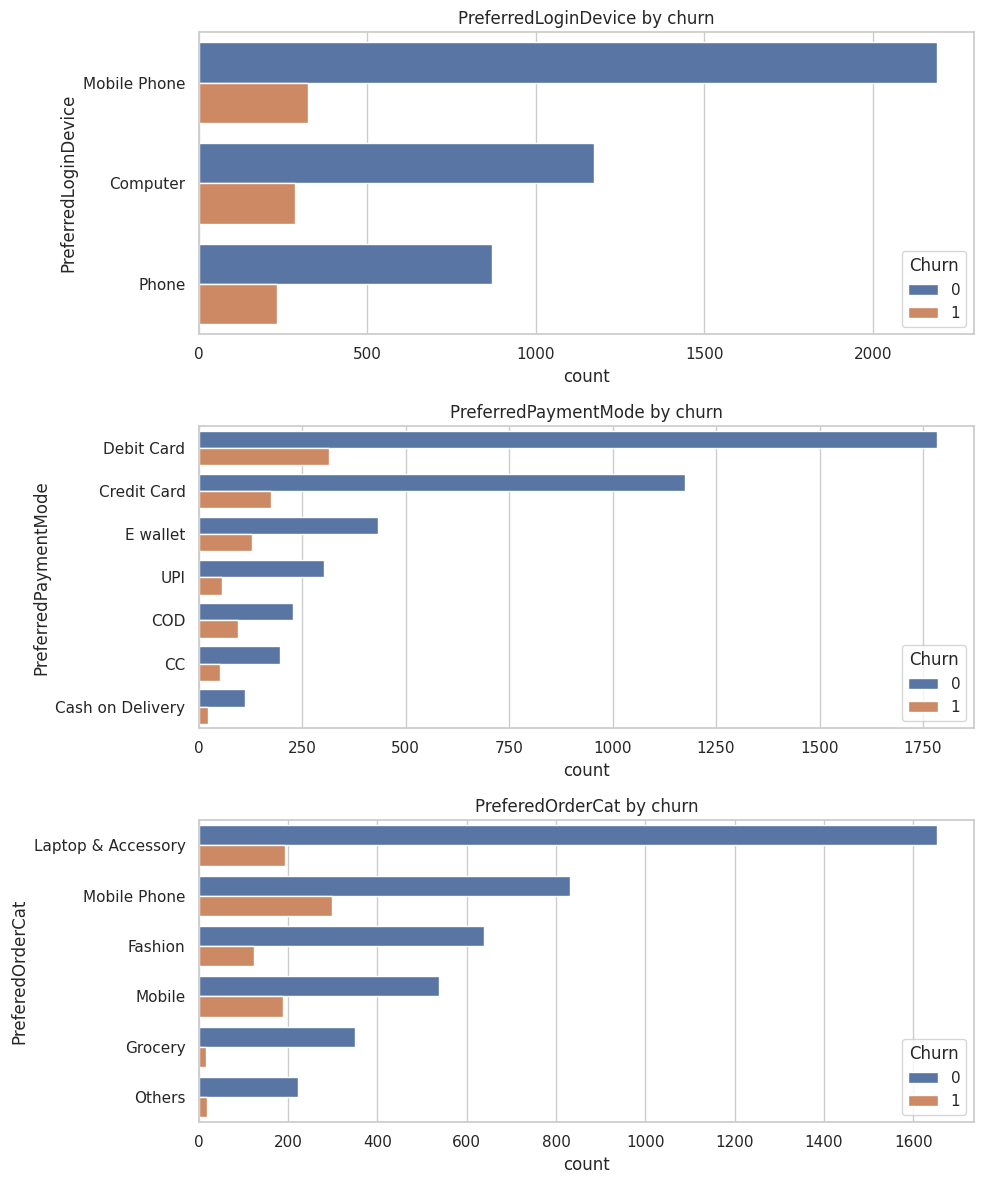

In [18]:
# Categorical features requested in the assignment (plot only those available).
requested_cat = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]
available_cat = [c for c in requested_cat if c in df.columns]

if available_cat:
    fig, axes = plt.subplots(len(available_cat), 1, figsize=(10, 4 * len(available_cat)))
    if len(available_cat) == 1:
        axes = [axes]
    for ax, col in zip(axes, available_cat):
        order = df[col].value_counts().index
        sns.countplot(data=df, y=col, hue="Churn", order=order, ax=ax)
        ax.set_title(f"{col} by churn")
    plt.tight_layout()
    plt.show()
else:
    print("None of the requested categorical EDA columns were found.")


### 1.4 Separate features and target, then split the data
I remove the target from the input features. The split is stratified so that the proportion of churned and retained customers stays approximately the same in both sets.

**Why is `random_state` essential?**  
Setting `random_state` fixes the random seed used by the splitting process. This makes the same rows go to the training and testing sets every time the notebook is run, assuming the data and code are unchanged. Reproducibility makes model comparisons fair and helps another person verify the results. `stratify=y` separately preserves the target-class proportions.

In [19]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Remove columns that are entirely missing; an imputer cannot learn a value from them.
all_missing_cols = X.columns[X.isna().all()].tolist()
if all_missing_cols:
    print("Dropping entirely missing columns:", all_missing_cols)
    X = X.drop(columns=all_missing_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("Proportion"))
print("Testing class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("Proportion"))


Training shape: (4059, 18)
Testing shape: (1015, 18)

Training class proportions:


,Proportion
Churn,
0,0.834196
1,0.165804


Testing class proportions:


,Proportion
Churn,
0,0.834483
1,0.165517


## Part 2: Preprocessing Pipelines

### 2.1 Identify numerical and categorical columns
The numerical pipeline uses the median to fill missing values and then applies Min-Max scaling. The categorical pipeline fills missing values with the most frequent category and applies one-hot encoding. All preprocessing is fitted using training data only.

In [20]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

# sparse_output is used in recent scikit-learn versions; sparse is the older argument.
try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=True)

num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])


Numerical columns: ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical columns: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


### Attribute inspection: `SimpleImputer.statistics_`
After fitting the numerical imputer on the training data, `statistics_` contains the learned replacement value for each input column. The attribute is named `statistics_` because it is shared by the different imputation strategies: it can contain means, medians, most-frequent values, or constants. A dedicated `median_` attribute would not work consistently across all strategies.

In [21]:
if num_cols:
    median_imputer = SimpleImputer(strategy="median")
    median_imputer.fit(X_train[num_cols])
    print("Learned medians (statistics_):")
    display(pd.Series(median_imputer.statistics_, index=num_cols, name="Median"))
else:
    print("There are no numerical columns to impute.")


Learned medians (statistics_):


,Median
Tenure,9.00
CityTier,1.00
WarehouseToHome,13.00
HourSpendOnApp,3.00
NumberOfDeviceRegistered,4.00
SatisfactionScore,3.00
NumberOfAddress,3.00
Complain,0.00
OrderAmountHikeFromlastYear,15.00
CouponUsed,1.00


### Sparse matrix inspection: `OneHotEncoder`
One-hot encoding can create many columns, especially when a categorical feature has many distinct values. Most entries in the resulting matrix are zeros. A sparse matrix stores mainly the non-zero entries, reducing memory use compared with a dense NumPy array. `handle_unknown="ignore"` prevents an error if the test set contains a category that was not present during fitting.

In [22]:
if cat_cols:
    categorical_imputer = SimpleImputer(strategy="most_frequent")
    X_train_cat_filled = categorical_imputer.fit_transform(X_train[cat_cols])
    encoder_for_inspection = OneHotEncoder(handle_unknown="ignore")
    encoded_cat = encoder_for_inspection.fit_transform(X_train_cat_filled)
    print("Encoded output type:", type(encoded_cat))
    print("Encoded matrix shape:", encoded_cat.shape)
    print("Stored non-zero values:", encoded_cat.nnz if hasattr(encoded_cat, "nnz") else "Not a sparse matrix")
else:
    print("There are no categorical columns to encode.")


Encoded output type: <class 'scipy.sparse._csr.csr_matrix'>
Encoded matrix shape: (4059, 21)
Stored non-zero values: 20295


### 2.2 Combine preprocessing with `ColumnTransformer` and a master `Pipeline`
The `ColumnTransformer` applies the numerical pipeline only to numerical columns and the categorical pipeline only to categorical columns. The master pipeline then connects preprocessing to a classifier.

**What happens inside `pipeline.fit(X_train, y_train)`?**
1. The pipeline calls `fit_transform` on the preprocessing step using `X_train`.
2. Inside the `ColumnTransformer`, each column-specific transformer is fitted on its assigned training columns and transforms those columns.
3. The transformed numerical and categorical outputs are combined into one feature matrix.
4. The final estimator receives the transformed training matrix and `y_train`, then learns the relationship between the features and the target using its own `fit` method.
5. During `predict`, the already-fitted transformers only transform new data; they are not fitted again. The final estimator then predicts from the transformed data.

The key difference is that transformers learn preprocessing parameters and change the feature representation, while the final estimator learns the predictive model using both transformed features and target labels.

In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ],
    remainder="drop"
)

baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

baseline_pipeline.fit(X_train, y_train)
print("Master pipeline fitted successfully.")
print("Test accuracy:", round(baseline_pipeline.score(X_test, y_test), 4))


Master pipeline fitted successfully.
Test accuracy: 0.8818


## Part 3: Model Complexity, Bias-Variance and Regularization

### 3.1 Underfitting versus overfitting
A shallow decision tree (`max_depth=1`) is used as a high-bias baseline. I compare it with a deeper tree. Both models use the same preprocessing and training/test split.

As model complexity increases, bias generally decreases because the model can represent more patterns. Variance generally increases because a more flexible model can react more strongly to small changes in the training data. Very high complexity can therefore lead to overfitting.

In [24]:
shallow_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE))
])

complex_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE))
])

shallow_tree.fit(X_train, y_train)
complex_tree.fit(X_train, y_train)

complexity_results = pd.DataFrame([
    {
        "Model": "Shallow Decision Tree (depth=1)",
        "Training Accuracy": accuracy_score(y_train, shallow_tree.predict(X_train)),
        "Testing Accuracy": accuracy_score(y_test, shallow_tree.predict(X_test))
    },
    {
        "Model": "Deeper Decision Tree (depth=10)",
        "Training Accuracy": accuracy_score(y_train, complex_tree.predict(X_train)),
        "Testing Accuracy": accuracy_score(y_test, complex_tree.predict(X_test))
    }
])
display(complexity_results.round(4))


,Model,Training Accuracy,Testing Accuracy
0,Shallow Decision Tree (depth=1),0.8436,0.8246
1,Deeper Decision Tree (depth=10),0.9665,0.9261


**Why can increasing model complexity solve underfitting?**  
Underfitting happens when the model is too simple to capture important patterns in the training data. Increasing its complexity gives it more flexibility and can reduce this limitation. Simply adding more training examples does not directly fix a model that cannot represent the underlying relationship; it gives the same restricted model more examples to learn from. More data is especially useful for reducing variance, while a model with insufficient capacity needs a more suitable level of complexity.

The comparison above should be interpreted using both training and testing scores. A large training score with a noticeably lower test score is a warning sign of overfitting. Low scores on both sets suggest underfitting.

### 3.2 Logistic Regression: L1, L2 and Elastic Net
Regularization adds a penalty to the model's objective to discourage overly large coefficients. This can reduce overfitting.

- **L2 (Ridge):** penalizes the squared magnitude of coefficients and usually shrinks them toward zero.
- **L1 (Lasso):** penalizes the absolute magnitude and can make some coefficients exactly zero, producing a sparse model.
- **Elastic Net:** combines L1 and L2 penalties. With `l1_ratio=0.5`, the two penalty types are mixed equally.

The models below use `solver="saga"` and `max_iter=2000`, as requested. The preprocessing pipeline scales numerical features before fitting each classifier.

In [25]:
regularized_models = {
    "Logistic Regression - L2": LogisticRegression(
        penalty="l2", solver="saga", max_iter=2000, random_state=RANDOM_STATE
    ),
    "Logistic Regression - L1": LogisticRegression(
        penalty="l1", solver="saga", max_iter=2000, random_state=RANDOM_STATE
    ),
    "Logistic Regression - Elastic Net": LogisticRegression(
        penalty="elasticnet", l1_ratio=0.5, solver="saga",
        max_iter=2000, random_state=RANDOM_STATE
    )
}

regularization_pipelines = {}
regularization_rows = []

for name, model in regularized_models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    regularization_pipelines[name] = pipe
    regularization_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0)
    })

regularization_results = pd.DataFrame(regularization_rows).set_index("Model")
display(regularization_results.round(4))


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression - L2,0.8818,0.7500,0.4286,0.5455
Logistic Regression - L1,0.8837,0.7232,0.4821,0.5786
Logistic Regression - Elastic Net,0.8818,0.7353,0.4464,0.5556


## Part 4: Ensemble Learning

### 4.1 Bagging versus Pasting and Out-of-Bag evaluation
Bagging trains multiple models on bootstrap samples (sampling with replacement). Pasting trains models on random subsets sampled without replacement. Both combine predictions from multiple estimators.

`n_jobs=-1` tells scikit-learn to use all available CPU cores for the parallelizable work.

When `bootstrap=False`, `BaggingClassifier` uses **Pasting** because each estimator's training subset is sampled without replacement.

OOB evaluation uses training examples that were not selected in a particular estimator's bootstrap sample to estimate performance. It provides an internal validation estimate without requiring a separate validation split for that estimate. I compare the OOB score with test accuracy; they are not expected to be exactly equal.

In [26]:
# Fit preprocessing on training data only, then transform train and test.
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Handle scikit-learn API differences: newer versions use 'estimator',
# while older versions used 'base_estimator'.
import inspect
bagging_params = inspect.signature(BaggingClassifier).parameters
base_arg = "estimator" if "estimator" in bagging_params else "base_estimator"

bagging_kwargs = {
    base_arg: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "n_estimators": 100,
    "max_samples": 1.0,
    "n_jobs": -1,
    "random_state": RANDOM_STATE
}

bagging_model = BaggingClassifier(
    **bagging_kwargs, bootstrap=True, oob_score=True
)
bagging_model.fit(X_train_transformed, y_train)

pasting_model = BaggingClassifier(
    **bagging_kwargs, bootstrap=False, oob_score=False
)
pasting_model.fit(X_train_transformed, y_train)

bagging_test_accuracy = accuracy_score(y_test, bagging_model.predict(X_test_transformed))
pasting_test_accuracy = accuracy_score(y_test, pasting_model.predict(X_test_transformed))

print("Bagging OOB score:", round(bagging_model.oob_score_, 4))
print("Bagging test accuracy:", round(bagging_test_accuracy, 4))
print("Pasting test accuracy:", round(pasting_test_accuracy, 4))


Bagging OOB score: 0.9576
Bagging test accuracy: 0.9665
Pasting test accuracy: 0.9527


### 4.2 Boosting: AdaBoost
AdaBoost trains weak learners sequentially. After each iteration, it increases the relative weights of misclassified training instances so that the next learner pays more attention to examples that were difficult for the previous learner. Correctly classified examples receive relatively less emphasis. The process focuses the ensemble on errors made in earlier rounds.

In [27]:
ada_params = inspect.signature(AdaBoostClassifier).parameters
ada_base_arg = "estimator" if "estimator" in ada_params else "base_estimator"

ada_kwargs = {
    ada_base_arg: DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
    "n_estimators": 100,
    "learning_rate": 0.5,
    "random_state": RANDOM_STATE
}
adaboost_model = AdaBoostClassifier(**ada_kwargs)
adaboost_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", adaboost_model)
])
adaboost_pipeline.fit(X_train, y_train)

ada_pred = adaboost_pipeline.predict(X_test)
ada_results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, ada_pred),
    "Precision": precision_score(y_test, ada_pred, zero_division=0),
    "Recall": recall_score(y_test, ada_pred, zero_division=0),
    "F1-Score": f1_score(y_test, ada_pred, zero_division=0)
}], index=["AdaBoost"])
display(ada_results.round(4))
print(classification_report(y_test, ada_pred, zero_division=0))


,Accuracy,Precision,Recall,F1-Score
AdaBoost,0.8739,0.75,0.3571,0.4839


              precision    recall  f1-score   support

           0       0.88      0.98      0.93       847
           1       0.75      0.36      0.48       168

    accuracy                           0.87      1015
   macro avg       0.82      0.67      0.71      1015
weighted avg       0.86      0.87      0.85      1015



### 4.3 Voting Classifiers: Hard versus Soft Voting
The voting ensemble combines three different estimators: Logistic Regression, Random Forest and SVC with `probability=True`.

- **Hard voting** selects the class receiving the majority of individual predictions.
- **Soft voting** averages the predicted class probabilities and selects the class with the highest average probability. It requires estimators that can estimate probabilities; therefore, SVC is configured with `probability=True`.

The preprocessing step is shared and is fitted only on the training set.

In [28]:
voting_estimators = [
    ("logistic", LogisticRegression(max_iter=2000, solver="saga", random_state=RANDOM_STATE)),
    ("random_forest", RandomForestClassifier(
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1
    )),
    ("svc", SVC(probability=True, random_state=RANDOM_STATE))
]

hard_voting = VotingClassifier(estimators=voting_estimators, voting="hard", n_jobs=-1)
soft_voting = VotingClassifier(estimators=voting_estimators, voting="soft", n_jobs=-1)

hard_voting_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", hard_voting)
])
soft_voting_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", soft_voting)
])

hard_voting_pipeline.fit(X_train, y_train)
soft_voting_pipeline.fit(X_train, y_train)

hard_pred = hard_voting_pipeline.predict(X_test)
soft_pred = soft_voting_pipeline.predict(X_test)

voting_results = pd.DataFrame([
    {
        "Model": "Hard Voting",
        "Accuracy": accuracy_score(y_test, hard_pred),
        "Precision": precision_score(y_test, hard_pred, zero_division=0),
        "Recall": recall_score(y_test, hard_pred, zero_division=0),
        "F1-Score": f1_score(y_test, hard_pred, zero_division=0)
    },
    {
        "Model": "Soft Voting",
        "Accuracy": accuracy_score(y_test, soft_pred),
        "Precision": precision_score(y_test, soft_pred, zero_division=0),
        "Recall": recall_score(y_test, soft_pred, zero_division=0),
        "F1-Score": f1_score(y_test, soft_pred, zero_division=0)
    }
]).set_index("Model")
display(voting_results.round(4))


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Hard Voting,0.9015,0.9048,0.4524,0.6032
Soft Voting,0.9044,0.8515,0.5119,0.6394


## 5. Overall comparison and conclusion
The following table collects the main test-set results produced in this notebook. Accuracy measures the proportion of correct predictions. Precision measures how many predicted churn cases were actually churn cases. Recall measures how many actual churn cases were detected. F1-score is the harmonic mean of precision and recall.

For churn prediction, accuracy should not be interpreted alone, especially if retained customers are much more common than churned customers. Recall and F1-score help show how well the model detects the minority churn class.

The best model should be selected based on the assignment's evaluation goal and the observed test results, not by assuming that one algorithm is always best.

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Bagging,0.9665,0.9241,0.8690,0.8957
Pasting,0.9527,0.8488,0.8690,0.8588
Soft Voting,0.9044,0.8515,0.5119,0.6394
Hard Voting,0.9015,0.9048,0.4524,0.6032
Logistic Regression - L1,0.8837,0.7232,0.4821,0.5786
Logistic Regression - Elastic Net,0.8818,0.7353,0.4464,0.5556
Baseline Logistic Regression,0.8818,0.7500,0.4286,0.5455
Logistic Regression - L2,0.8818,0.7500,0.4286,0.5455
AdaBoost,0.8739,0.7500,0.3571,0.4839


<Figure size 1100x500 with 0 Axes>

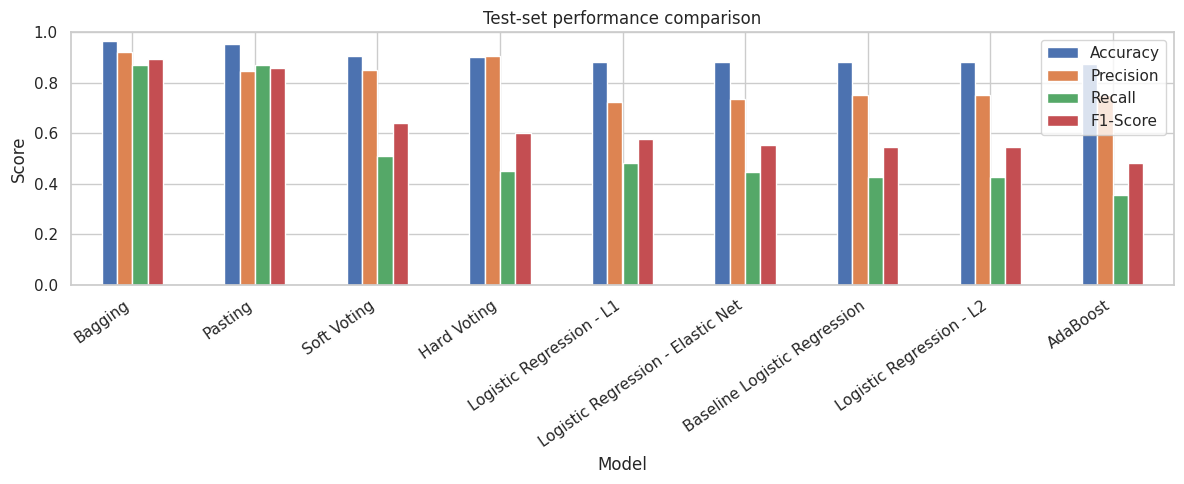

In [29]:
all_results = []

# Baseline Logistic Regression
baseline_pred = baseline_pipeline.predict(X_test)
all_results.append({
    "Model": "Baseline Logistic Regression",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-Score": f1_score(y_test, baseline_pred, zero_division=0)
})

for model_name, row in regularization_results.iterrows():
    all_results.append({
        "Model": model_name,
        "Accuracy": row["Accuracy"],
        "Precision": row["Precision"],
        "Recall": row["Recall"],
        "F1-Score": row["F1-Score"]
    })

all_results.extend([
    {
        "Model": "Bagging",
        "Accuracy": bagging_test_accuracy,
        "Precision": precision_score(y_test, bagging_model.predict(X_test_transformed), zero_division=0),
        "Recall": recall_score(y_test, bagging_model.predict(X_test_transformed), zero_division=0),
        "F1-Score": f1_score(y_test, bagging_model.predict(X_test_transformed), zero_division=0)
    },
    {
        "Model": "Pasting",
        "Accuracy": pasting_test_accuracy,
        "Precision": precision_score(y_test, pasting_model.predict(X_test_transformed), zero_division=0),
        "Recall": recall_score(y_test, pasting_model.predict(X_test_transformed), zero_division=0),
        "F1-Score": f1_score(y_test, pasting_model.predict(X_test_transformed), zero_division=0)
    },
    {
        "Model": "AdaBoost",
        "Accuracy": accuracy_score(y_test, ada_pred),
        "Precision": precision_score(y_test, ada_pred, zero_division=0),
        "Recall": recall_score(y_test, ada_pred, zero_division=0),
        "F1-Score": f1_score(y_test, ada_pred, zero_division=0)
    },
    {
        "Model": "Hard Voting",
        "Accuracy": accuracy_score(y_test, hard_pred),
        "Precision": precision_score(y_test, hard_pred, zero_division=0),
        "Recall": recall_score(y_test, hard_pred, zero_division=0),
        "F1-Score": f1_score(y_test, hard_pred, zero_division=0)
    },
    {
        "Model": "Soft Voting",
        "Accuracy": accuracy_score(y_test, soft_pred),
        "Precision": precision_score(y_test, soft_pred, zero_division=0),
        "Recall": recall_score(y_test, soft_pred, zero_division=0),
        "F1-Score": f1_score(y_test, soft_pred, zero_division=0)
    }
])

final_comparison = pd.DataFrame(all_results).set_index("Model").sort_values("F1-Score", ascending=False)
display(final_comparison.round(4))

plt.figure(figsize=(11, 5))
final_comparison[["Accuracy", "Precision", "Recall", "F1-Score"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1)
)
plt.title("Test-set performance comparison")
plt.ylabel("Score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


Best model by test F1-score: Bagging


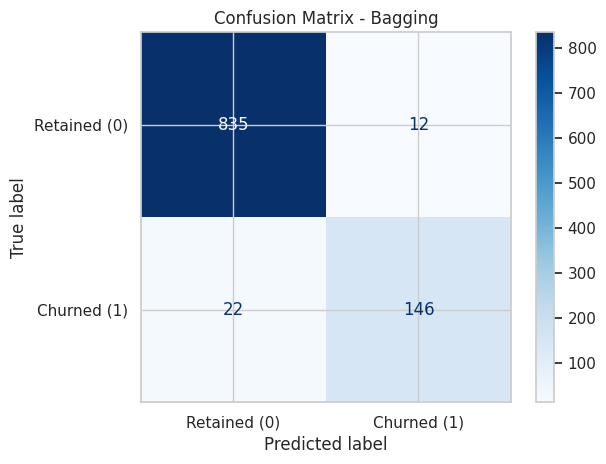

              precision    recall  f1-score   support

Retained (0)       0.97      0.99      0.98       847
 Churned (1)       0.92      0.87      0.90       168

    accuracy                           0.97      1015
   macro avg       0.95      0.93      0.94      1015
weighted avg       0.97      0.97      0.97      1015



In [30]:
# Confusion matrix for the model with the highest F1-score in the comparison.
best_model_name = final_comparison.index[0]
predictions = {
    "Baseline Logistic Regression": baseline_pred,
    "Logistic Regression - L2": regularization_pipelines["Logistic Regression - L2"].predict(X_test),
    "Logistic Regression - L1": regularization_pipelines["Logistic Regression - L1"].predict(X_test),
    "Logistic Regression - Elastic Net": regularization_pipelines["Logistic Regression - Elastic Net"].predict(X_test),
    "Bagging": bagging_model.predict(X_test_transformed),
    "Pasting": pasting_model.predict(X_test_transformed),
    "AdaBoost": ada_pred,
    "Hard Voting": hard_pred,
    "Soft Voting": soft_pred
}
best_pred = predictions[best_model_name]

print("Best model by test F1-score:", best_model_name)
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["Retained (0)", "Churned (1)"], cmap="Blues"
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

print(classification_report(y_test, best_pred, target_names=["Retained (0)", "Churned (1)"], zero_division=0))


## Final notes
- The test set was kept separate from fitting the preprocessing steps and model parameters.
- The preprocessing pipeline handles missing numerical and categorical values and unknown categories.
- The results above are generated from the actual dataset when the notebook is executed; they are not hard-coded.
- Before submission, I will confirm that all cells run from top to bottom, check the displayed metrics, and write my name in the student field.

**Conclusion:** This assignment demonstrates how a complete scikit-learn workflow can be built using pipelines and ensemble methods. The final model comparison should be discussed using the values produced in the notebook, with particular attention to recall and F1-score for the churn class.